# Symbolic regression with PySR

## Installation
Install the required packages with pip:
```
pip install numpy pandas matplotlib sympy "scikit-learn>=1.4" pysr jupyter
```
or with conda:
```
conda install -c conda-forge numpy pandas matplotlib sympy "scikit-learn>=1.4" pysr jupyter
```

## Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy
import pysr
from scipy.integrate import nquad, IntegrationWarning
from sklearn.metrics import root_mean_squared_error, r2_score

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## Helper functions
We define three helpers. The first is a custom loss function that PySR uses to score each candidate equation by its root mean squared error (RMSE). Because PySR runs its search in Julia, we write the loss in Julia so it can be evaluated inside that backend, where it is called for every candidate equation at every iteration. If a candidate fails to evaluate (e.g., division by zero), the function returns an infinite loss so the search discards it.

The second helper, `safe_rmse`, computes RMSE in Python when we evaluate the finished equations. An equation that behaves well on the training data can still produce non-finite values on new data (e.g., a denominator that reaches zero only in the test set), so `safe_rmse` returns NaN in that case instead of raising an error.

The third helper, `decs`, computes directional ensemble contribution scores (DECS), a novel variable importance score which measures how strongly and in which direction each variable drives the outcome across a set of equations. For each equation containing a variable, we take the partial derivative of the equation with respect to that variable, integrate it over the observed range of every variable in the derivative, and divide by the variable's range. We then sum these values across all equations and divide every score by the largest absolute score, so the variable with the largest contribution has a score of 1 or -1 and all others fall in between. The sign of the score gives the direction of the effect, and its magnitude gives the strength.

In [2]:
# Custom loss: RMSE of each candidate equation; equations that fail to evaluate get infinite loss
loss_function = """
function f(tree, dataset::Dataset{T,L}, options) where {T,L}
    ypred, completed = eval_tree_array(tree, dataset.X, options)
    if !completed
        return L(Inf)
    end
    y = dataset.y
    return sqrt( (1 / length(y)) * sum(i -> (ypred[i] - y[i])^2, eachindex(y)))
end
"""

def safe_rmse(y_true, y_pred):
    """RMSE that returns NaN instead of failing on non-finite predictions."""
    y_pred = np.asarray(y_pred, dtype=float)
    if not np.all(np.isfinite(y_pred)):
        return np.nan
    return root_mean_squared_error(y_true, y_pred)


def decs(equations, X):
    """Directional ensemble contribution scores (DECS) for each variable across equations."""
    ranges = {c: (X[c].min(), X[c].max()) for c in X.columns}
    scores = {}

    for expr in equations:
        for var in expr.free_symbols:
            # Partial derivative and the variables to integrate over
            deriv = sympy.diff(expr, var)
            syms = list(deriv.free_symbols | {var})
            f = sympy.lambdify(syms, sympy.re(deriv), "numpy")

            # Treat undefined points (e.g., division by zero) as 0
            def integrand(*args):
                try:
                    val = float(f(*args))
                    return val if np.isfinite(val) else 0.0
                except (ZeroDivisionError, ValueError, OverflowError):
                    return 0.0

            # Integrate over observed ranges; divergent integrals contribute 0
            with warnings.catch_warnings():
                warnings.simplefilter("error", IntegrationWarning)
                try:
                    integral, _ = nquad(integrand, [ranges[str(s)] for s in syms])
                except IntegrationWarning:
                    integral = 0.0

            # Scale by the variable's range and add to its running total
            lo, hi = ranges[str(var)]
            scores[str(var)] = scores.get(str(var), 0.0) + integral / (hi - lo)

    # Scale by the largest magnitude so scores fall between -1 and 1
    scores = pd.Series(scores, name="DECS")
    scores = scores / scores.abs().max()
    return scores.sort_values(key=abs, ascending=False)


## Load data
The data come from the paper *Interpretable Machine Learning to Understand Wildfire Toxicity: Bridging Chemicals, Omics, and Toxicological Outcomes via Symbolic Regression with Novel Feature Scoring*. X contains a subset of chemical measurements from several wildfire exposure scenarios, and y contains the total protein (TP) measured in bronchoalveolar lavage fluid (BALF) from mice exposed to each scenario. The data are already split into training and test sets. Our goal is to predict BALF TP from the chemical measurements.

In [3]:
y_train = np.ravel(pd.read_pickle("train_y"))
y_test = np.ravel(pd.read_pickle("test_y"))

X_train = pd.read_pickle("train_x")
X_test = pd.read_pickle("test_x")
feature_names = X_train.columns.tolist()

## Define the model
Model parameters are described below. Together they define which equations PySR can build and how the evolutionary search runs.

In [5]:
model = pysr.PySRRegressor(
    # Search space
    binary_operators=["-", "+", "*", "/", "^"],    # Defines which operators PySR is allowed to use in equations
    constraints={"^": (1, 1),                      # Exponent base and power limited to single nodes to avoid overly complex expressions
                 "/": (-1, 2)},                    # Denominator limited to complexity 2 to avoid overly complex expressions
    complexity_of_variables=2,                     # Set variables to add more complexity than constants (1)

    # Evolutionary settings (PySR defaults)
    populations=15,                                # Independent populations evolving in parallel
    population_size=33,                            # Number of individuals in each population
    parsimony=0.0032,                              # A multiplicative factor that penalizes the total complexity

    # Objective and selection
    loss_function=loss_function,                   # Custom RMSE loss defined above

    # Training mechanics
    niterations=50,                               # Number of iterations to run the evolutionary search

    # Reproducibility                             
    random_state=17,                              # Set seed
    deterministic=True,                           # Make search give the same result every run
    procs = 0,                                    # Turns off multiprocessing parallelization

    # Housekeeping
    temp_equation_file=True,                      # Don't save intermediate files
    verbosity=0,                            
    progress=False,
)

## Apply model to training data

In [6]:
model.fit(X_train.values, y_train, variable_names=feature_names)

c:\Users\Jessie PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\pysr\sr.py:2059: UserWarning: Note: you are running with 10 features or more. Genetic algorithms like used in PySR scale poorly with large numbers of features. You should run PySR for more `niterations` to ensure it can find the correct variables, and consider using a larger `maxsize`.
  warnings.warn(


PySRRegressor.equations_ = [
	    pick     score                                           equation  \
	0         0.000000                                          2.2813215   
	1   >>>>  0.658267                              24.755009 + 58.834053   
	2         0.209886                               -16.407207 * Eugenol   
	3         0.017212                -35.984177 + (Eugenol * -23.947454)   
	4         0.007210        (-23.264503 - Benzokfluoranthene) * Eugenol   
	5         0.012681  ((-29.455376 - Benzokfluoranthene) * Eugenol) ...   
	6         0.002918  ((Eugenol * (-14.645505 - Acenaphthylene)) + -...   
	7         0.006559  Cr + (((-13.849169 - Benzokfluoranthene) / 0.3...   
	8         0.002219  (((Eugenol * (-12.354101 - Benzobfluoranthene)...   
	9         0.000224  ((Cr + (((-13.849169 - Benzokfluoranthene) / 0...   
	10        0.008614  (((Eugenol * (-9.15947 - Benzobfluoranthene)) ...   
	
	         loss  complexity  
	0   84.396730           1  
	1   22.623602           3  
	2   18.340418           4  
	3   17.719807           6  
	4   17.592506           7  
	5   17.151932           9  
	6   17.052120          11  
	7   16.940647          12  
	8   16.865625          14  
	9   16.858074          16  
	10  16.713486          17  
]

## Inspect the Hall of Fame
The Hall of Fame (HOF) holds the best equation PySR found at each complexity level. We evaluate every HOF equation on both the training and test sets. The score gives a measure of combined complexity and accuracy to prioritize well-performing, simple models

In [7]:
# Evaluate every HOF equation on train and test data
hof = model.equations_.copy().reset_index(drop=True)
hof["train_rmse"] = [safe_rmse(y_train, model.predict(X_train.values, index=i)) for i in range(len(hof))]
hof["test_rmse"] = [safe_rmse(y_test, model.predict(X_test.values, index=i)) for i in range(len(hof))]

pd.set_option("display.max_colwidth", 80)
print(hof[["complexity", "train_rmse", "test_rmse", "score", "equation"]].to_string())

    complexity  train_rmse  test_rmse     score                                                                                        equation
0            1   84.396729  74.212806  0.000000                                                                                       2.2813215
1            3   22.623604  19.449590  0.658267                                                                           24.755009 + 58.834053
2            4   18.340417  16.968874  0.209886                                                                            -16.407207 * Eugenol
3            6   17.719807  18.253395  0.017212                                                             -35.984177 + (Eugenol * -23.947454)
4            7   17.592506  16.664602  0.007210                                                     (-23.264503 - Benzokfluoranthene) * Eugenol
5            9   17.151931  17.800270  0.012681                                       ((-29.455376 - Benzokfluoranthene) * Eugenol) - 29

## Evaluate how performance varies with complexity across training and test sets

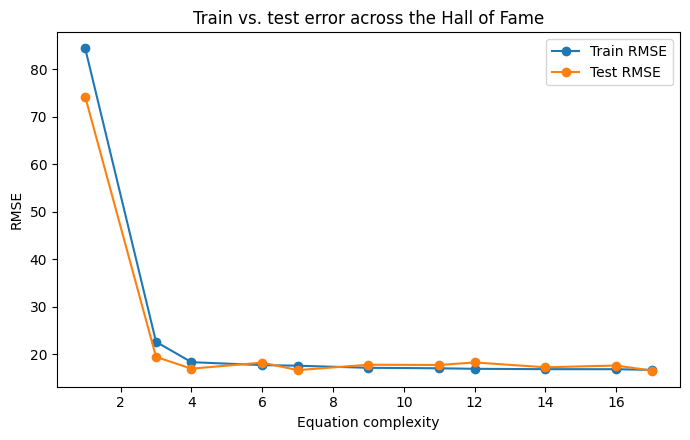

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(hof["complexity"], hof["train_rmse"], marker="o", label="Train RMSE")
ax.plot(hof["complexity"], hof["test_rmse"], marker="o", label="Test RMSE")
ax.set_xlabel("Equation complexity")
ax.set_ylabel("RMSE")
ax.set_title("Train vs. test error across the Hall of Fame")
ax.legend()

plt.tight_layout()
plt.show()

## Directional ensemble contribution scores (DECS)


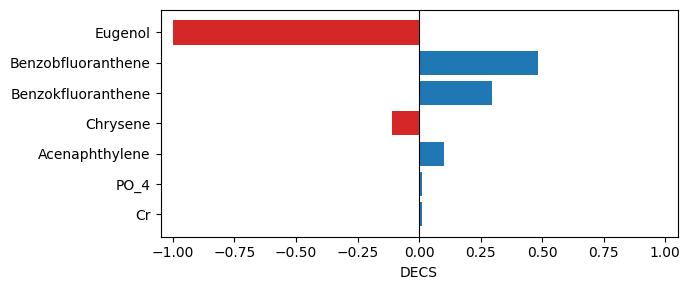

In [9]:
decs_scores = decs(hof["sympy_format"], X_train)

# Top 15 variables by absolute DECS
top = decs_scores.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, max(3, 0.35 * len(top))))
ax.barh(top.index, top.values, color=["tab:red" if v < 0 else "tab:blue" for v in top.values])
ax.axvline(0, color="k", linewidth=0.8)
ax.set_xlabel("DECS")
ax.set_xlim(-1.05, 1.05)
plt.tight_layout()
plt.show()

## Select equation
We select an equation from the HOF by weighing test performance and complexity alongside variable usage, DECS, and biological knowledge. 

In [ ]:
selected_idx = 4  # 5th HOF equation 

selected_expr = model.sympy(index=selected_idx)
print(f"Selected equation (HOF row {selected_idx + 1}):")
print(f"  Complexity: {hof.loc[selected_idx, 'complexity']}")
print(f"  y = {selected_expr}")
print(f"  LaTeX: {sympy.latex(selected_expr)}")

y_train_pred = model.predict(X_train.values, index=selected_idx)
y_test_pred = model.predict(X_test.values, index=selected_idx)

Selected equation (HOF row 5):
  Complexity: 7
  y = Eugenol*(-Benzokfluoranthene - 23.264503)
  LaTeX: Eugenol \left(- Benzokfluoranthene - 23.264503\right)


## Observed vs. predicted

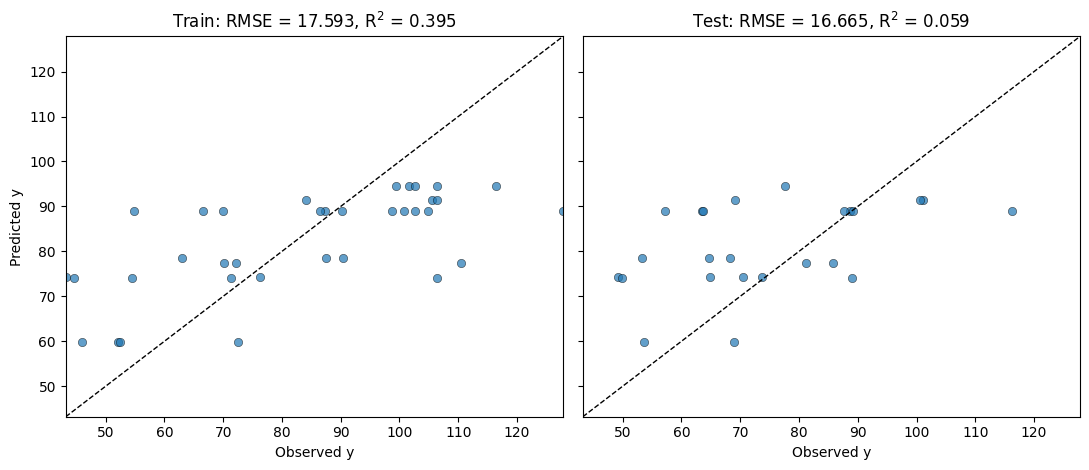

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
lims = [min(y_train.min(), y_test.min(), y_train_pred.min(), y_test_pred.min()),
        max(y_train.max(), y_test.max(), y_train_pred.max(), y_test_pred.max())]

for ax, y_obs, y_pred, label in [(axes[0], y_train, y_train_pred, "Train"),
                                 (axes[1], y_test, y_test_pred, "Test")]:
    ax.scatter(y_obs, y_pred, alpha=0.7, edgecolors="k", linewidths=0.4)
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Observed y")
    ax.set_title(f"{label}: RMSE = {safe_rmse(y_obs, y_pred):.3f}, "
                 f"R$^2$ = {r2_score(y_obs, y_pred):.3f}")
axes[0].set_ylabel("Predicted y")
plt.tight_layout()
plt.show()